# Shared teammate experience and MLB winning

Retrospective team-season regression, 2005–2024. See README and report for limitations, provenance, AI assistance, and review requirements. Run all cells. Pair histories use previous years, but target rosters are full-season participant lists.

In [1]:
from pathlib import Path
import sys, subprocess
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd().resolve()
if not (ROOT / 'src/analyze.py').exists(): ROOT = ROOT.parent
assert (ROOT / 'src/analyze.py').exists(), 'Start in the project root or notebooks folder'
result = subprocess.run([sys.executable, str(ROOT / 'src/analyze.py')], capture_output=True, text=True)
print(result.stdout)
result.check_returncode()

            model   MAE_pp  RMSE_pp            R2
    Mean baseline 6.866177 8.497992 -1.406799e-10
Linear regression 6.738120 8.119447  8.710622e-02
 Ridge regression 6.738531 8.120023  8.697661e-02
    Random forest 6.856676 8.320492  4.133837e-02
{
  "density_correlation": 0.3110758645268299,
  "density_tenure_correlation": 0.9095560180388016,
  "players_correlation": -0.2642979709529521,
  "linear_intercept": 0.5526641219964638,
  "mean_mae_gain_pp": 0.12805777321065745,
  "season_bootstrap_95_percentile_interval": [
    -0.10440934618980366,
    0.3605248926111186
  ],
  "python": "3.12.14",
  "sklearn": "1.8.0"
}
 group_type         group   n   MAE_pp  RMSE_pp       R2
     yearID          2020  30 7.215107 8.447875 0.146063
     yearID          2021  30 7.070142 8.704878 0.017590
     yearID          2022  30 7.130304 8.264028 0.139966
     yearID          2023  30 6.312569 7.842195 0.030433
     yearID          2024  30 5.962475 7.258885 0.084186
       lgID            AL  75 6

In [2]:
d = pd.read_csv(ROOT / 'data/processed/team_seasons.csv')
print('Table shape:', d.shape)
print('Missing cells:', d.isna().sum().sum())
display(d.head())
display(pd.read_csv(ROOT / 'outputs/descriptive_statistics.csv'))

Table shape: (600, 10)
Missing cells: 0


,yearID,teamID,lgID,name,W,L,players,density,tenure,win_pct
0,2005,ARI,NL,Arizona Diamondbacks,77,85,43,0.254707,0.338870,0.475309
1,2005,ATL,NL,Atlanta Braves,90,72,45,0.182828,0.341414,0.555556
2,2005,BAL,AL,Baltimore Orioles,74,88,46,0.314976,0.571981,0.456790
3,2005,BOS,AL,Boston Red Sox,95,67,52,0.220965,0.365008,0.586420
4,2005,CHA,AL,Chicago White Sox,99,63,38,0.337127,0.550498,0.611111


,Unnamed: 0,count,mean,std,min,25%,50%,75%,max
0,win_pct,600.0,0.499985,0.074340,0.253086,0.444444,0.500000,0.555556,0.716667
1,density,600.0,0.300968,0.085054,0.083051,0.240823,0.297005,0.354354,0.574751
2,tenure,600.0,0.481542,0.165233,0.129944,0.362995,0.456120,0.587888,1.086771
3,players,600.0,49.051667,6.163520,36.000000,45.000000,49.000000,53.000000,70.000000


## Model Metrics

In [3]:
display(pd.read_csv(ROOT / 'outputs/model_metrics.csv'))

,model,MAE_pp,RMSE_pp,R2
0,Mean baseline,6.866177,8.497992,-1.406799e-10
1,Linear regression,6.738120,8.119447,8.710622e-02
2,Ridge regression,6.738531,8.120023,8.697661e-02
3,Random forest,6.856676,8.320492,4.133837e-02


## Chronological Validation

In [4]:
display(pd.read_csv(ROOT / 'outputs/chronological_validation.csv'))

,validation_years,model,MAE_pp,RMSE_pp,R2
0,2011-2013,Mean baseline,6.165292,7.199170,-1.011967e-08
1,2011-2013,Linear regression,5.290491,6.543274,1.739140e-01
2,2011-2013,Ridge regression,5.299996,6.547754,1.727823e-01
3,2011-2013,Random forest,5.443686,6.813580,1.042521e-01
4,2014-2016,Mean baseline,5.297751,6.231049,-1.126316e-07
5,2014-2016,Linear regression,4.956990,6.170863,1.922480e-02
6,2014-2016,Ridge regression,4.952656,6.162392,2.191573e-02
7,2014-2016,Random forest,4.970175,6.325776,-3.063586e-02
8,2017-2019,Mean baseline,7.099327,8.575946,-1.893340e-07
9,2017-2019,Linear regression,6.517461,7.967286,1.369085e-01


## Coefficients

In [5]:
display(pd.read_csv(ROOT / 'outputs/coefficients.csv'))

,feature,coefficient_raw,change_for_reporting_unit_pp,reporting_unit
0,density,-0.150456,-1.504565,0.10 density
1,tenure,0.196559,1.965588,0.10 seasons per pair
2,players,-0.002173,-2.172910,10 players


## Error Groups

In [6]:
display(pd.read_csv(ROOT / 'outputs/error_groups.csv'))

,group_type,group,n,MAE_pp,RMSE_pp,R2
0,yearID,2020,30,7.215107,8.447875,0.146063
1,yearID,2021,30,7.070142,8.704878,0.017590
2,yearID,2022,30,7.130304,8.264028,0.139966
3,yearID,2023,30,6.312569,7.842195,0.030433
4,yearID,2024,30,5.962475,7.258885,0.084186
5,lgID,AL,75,6.546415,7.776380,0.152141
6,lgID,NL,75,6.929824,8.448594,0.022761
7,roster size,players <= 47,32,6.410864,7.577481,0.165475
8,roster size,players > 47,118,6.826867,8.260294,0.052377


## Feature Sensitivity

In [7]:
display(pd.read_csv(ROOT / 'outputs/feature_sensitivity.csv'))

,features,test_years,MAE_pp,RMSE_pp,R2
0,All features,2020-2024,6.738120,8.119447,8.710622e-02
1,All features,2021-2024,6.618873,8.035243,6.935056e-02
2,Density and roster size,2020-2024,6.874730,8.327824,3.964794e-02
3,Density and roster size,2021-2024,6.735375,8.252201,1.841552e-02
4,Tenure and roster size,2020-2024,6.754825,8.141274,8.219153e-02
5,Tenure and roster size,2021-2024,6.622509,8.053989,6.500298e-02
6,Roster size only,2020-2024,7.107598,8.580682,-1.955584e-02
7,Roster size only,2021-2024,6.969872,8.523605,-4.721242e-02
8,Density only,2020-2024,6.633527,8.130162,8.469518e-02
9,Density only,2021-2024,6.443864,8.004871,7.637268e-02


## Largest Errors

In [8]:
display(pd.read_csv(ROOT / 'outputs/largest_errors.csv'))

,yearID,teamID,lgID,name,win_pct,Linear regression,residual_pp
0,2021,LAN,NL,Los Angeles Dodgers,0.654321,0.467504,18.681656
1,2024,CHA,AL,Chicago White Sox,0.253086,0.432359,-17.927282
2,2021,SFN,NL,San Francisco Giants,0.660494,0.481917,17.857655
3,2020,PIT,NL,Pittsburgh Pirates,0.316667,0.492901,-17.623471
4,2022,LAN,NL,Los Angeles Dodgers,0.685185,0.514768,17.041766
5,2022,NYN,NL,New York Mets,0.623457,0.454567,16.888930
6,2021,TBA,AL,Tampa Bay Rays,0.617284,0.453105,16.417899
7,2023,ATL,NL,Atlanta Braves,0.641975,0.482284,15.969085
8,2020,TBA,AL,Tampa Bay Rays,0.666667,0.512154,15.451251
9,2020,SDN,NL,San Diego Padres,0.616667,0.479656,13.701057


## Visualizations

Five exploratory plots and three model interpretation/evaluation plots. Full discussion appears in the report.

fig01_win_distribution.png
fig02_density_distribution.png
fig03_density_vs_wins.png
fig04_tenure_vs_wins.png
fig05_roster_vs_wins.png
fig06_residuals.png
fig07_model_comparison.png
fig08_actual_predicted.png


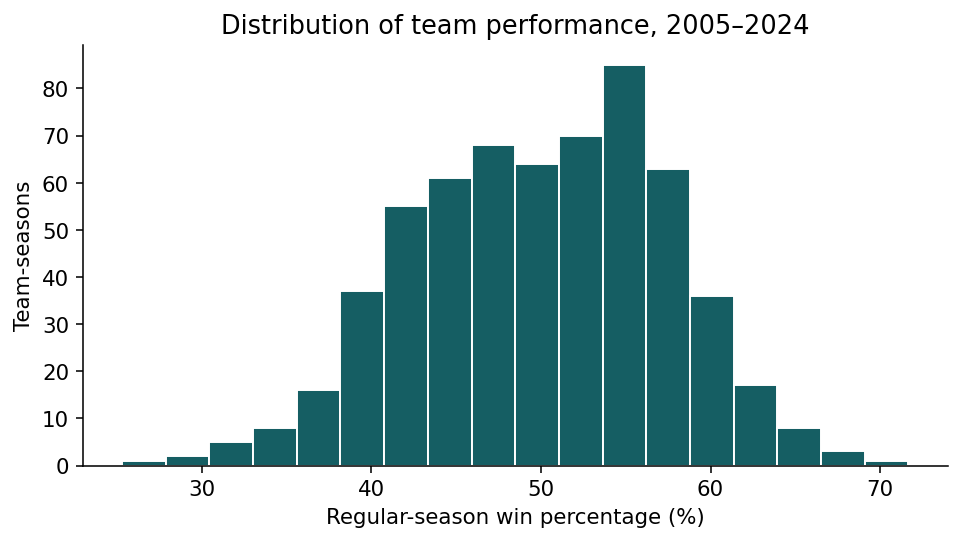

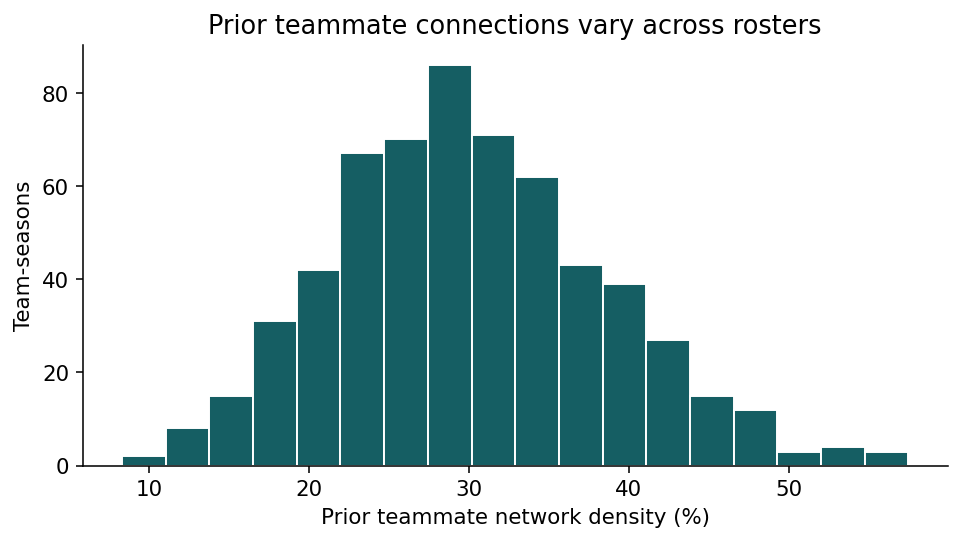

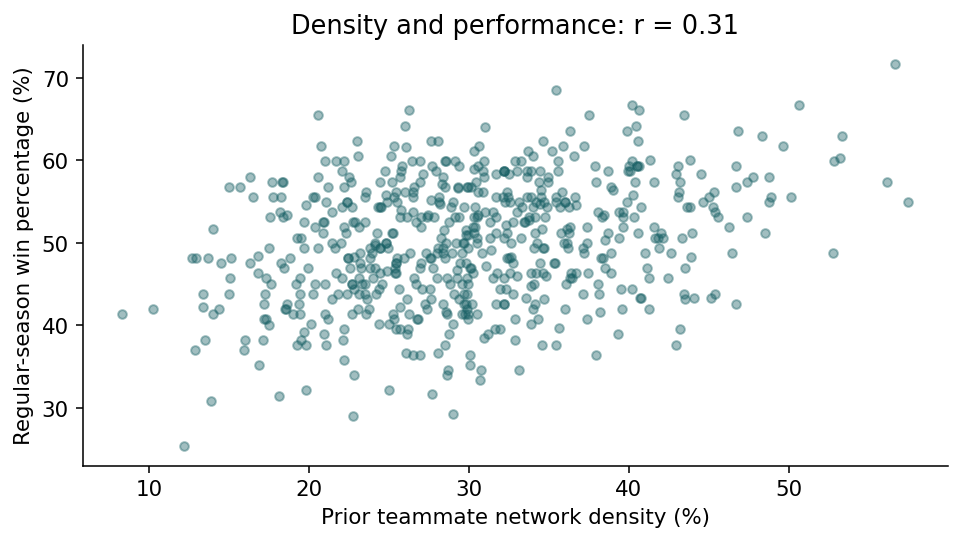

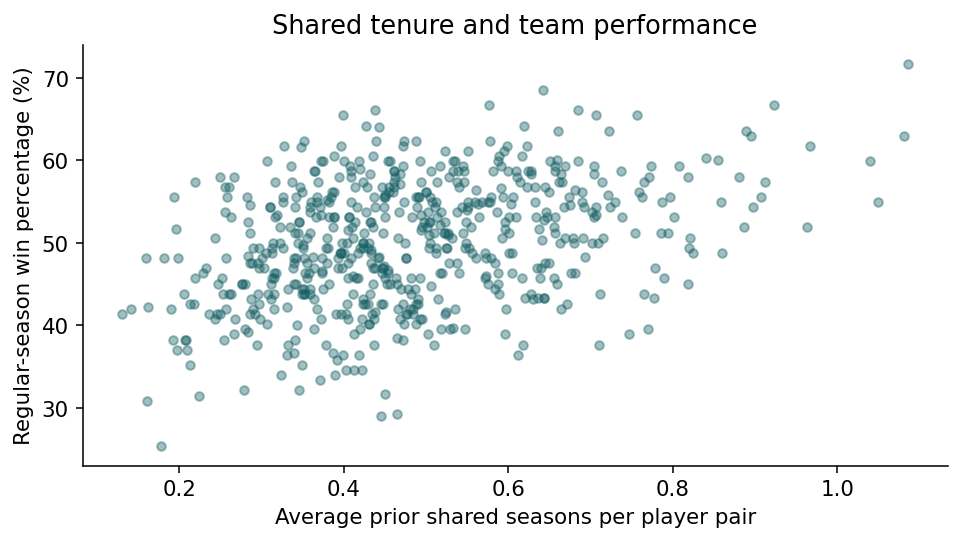

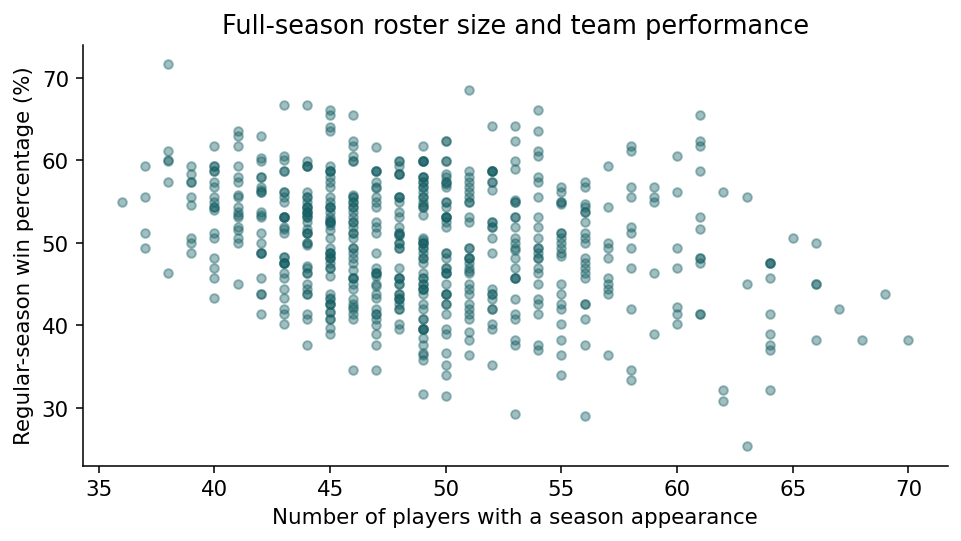

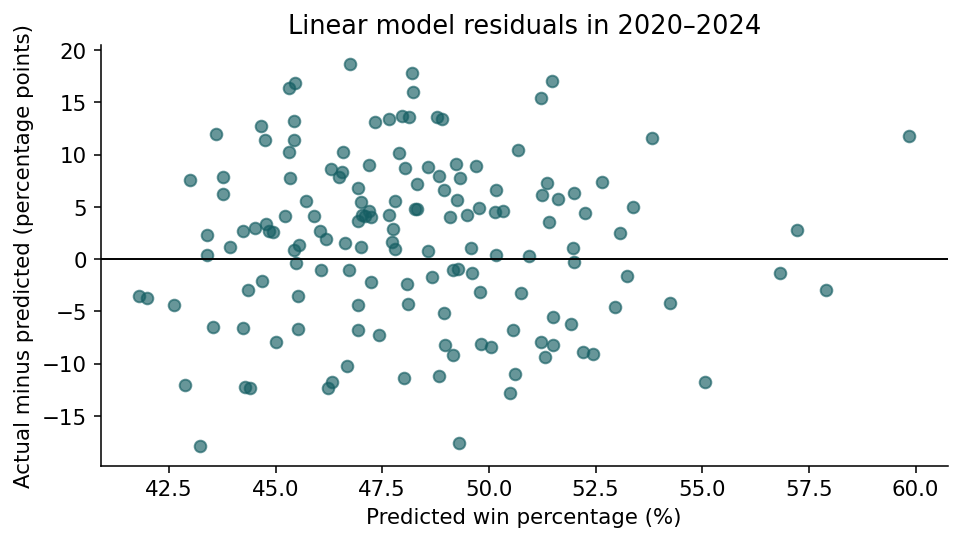

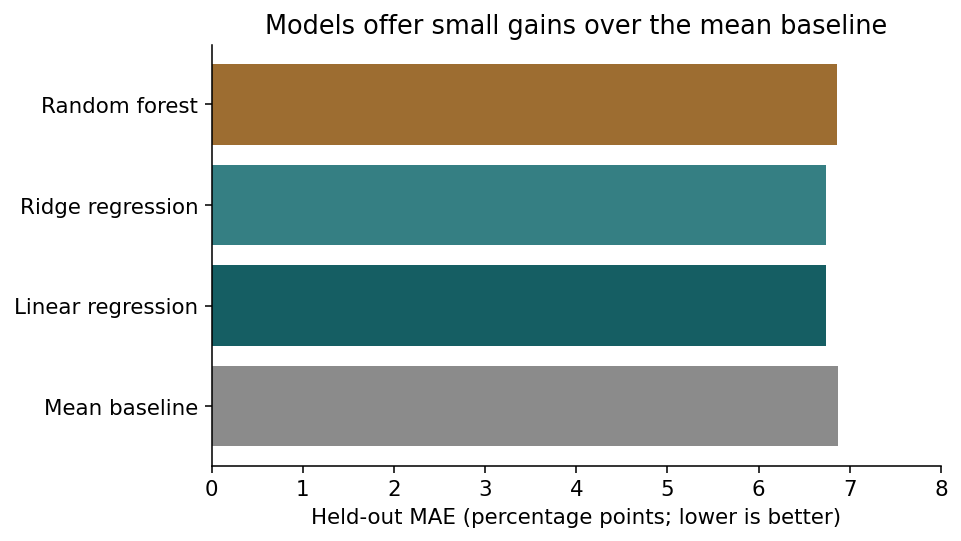

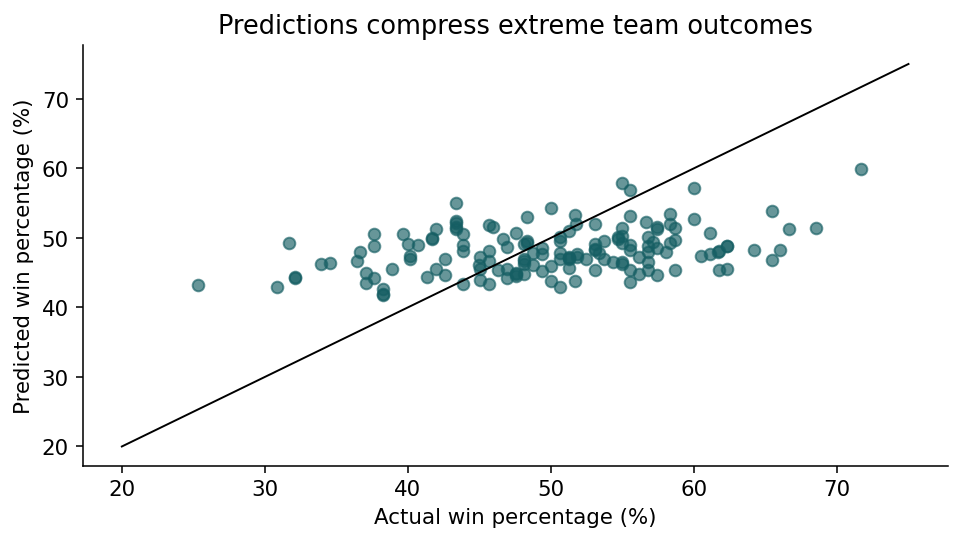

In [9]:
for figure in sorted((ROOT / 'outputs').glob('fig*.png')):
    print(figure.name)
    display(Image(filename=str(figure)))

## Interpretation

Linear and Ridge MAE is about 6.74 points versus 6.87 for the baseline. The gain is small. Correlated features complicate coefficients. Ablations reuse the inspected test period and are exploratory. Omitted talent/payroll and retrospective rosters prevent causal or preseason conclusions.